Original Dataset:
   Haemoglobin       RBC     Glucose  Cholesterol        BMI
0    14.245071  5.014672   78.111447   212.709658  28.753135
1    13.292604  5.136471   98.012500   162.335040  22.935821
2    14.471533  5.449831  110.104874   216.088178  25.384483
3    15.784545  5.432281  110.939612   230.669136  23.150899
4    13.148770  3.973398  100.998691   202.403047  23.262015

Dataset Shape: (200, 5)

Standardised Data:
   Haemoglobin       RBC   Glucose  Cholesterol       BMI
0     0.577318  0.275500 -1.517816     0.733661  0.847373
1    -0.104719  0.481170 -0.516799    -0.913256 -0.673997
2     0.739481  1.010313  0.091444     0.844116 -0.033612
3     1.679693  0.980679  0.133431     1.320817 -0.617749
4    -0.207714 -1.482808 -0.366595     0.396703 -0.588689

Covariance Matrix:
             Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.095147 -0.134197     0.065398 -0.031206
RBC             0.095147  1.000000 -0.032626    -0.101396 -0.142037

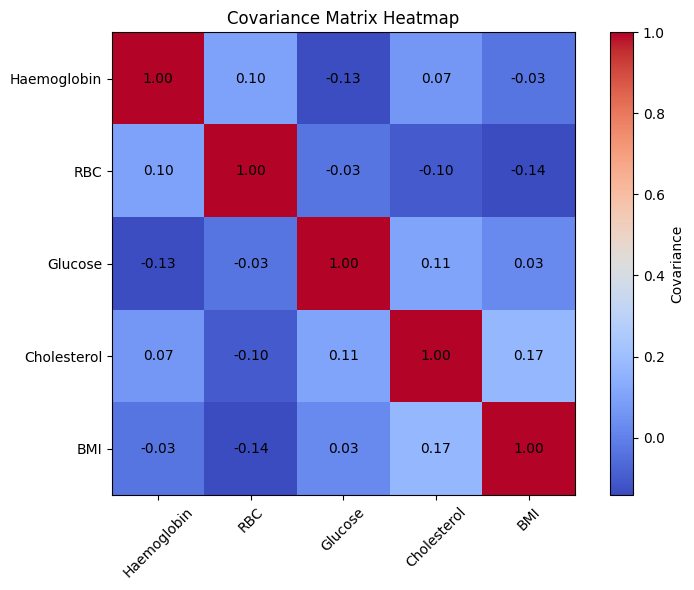

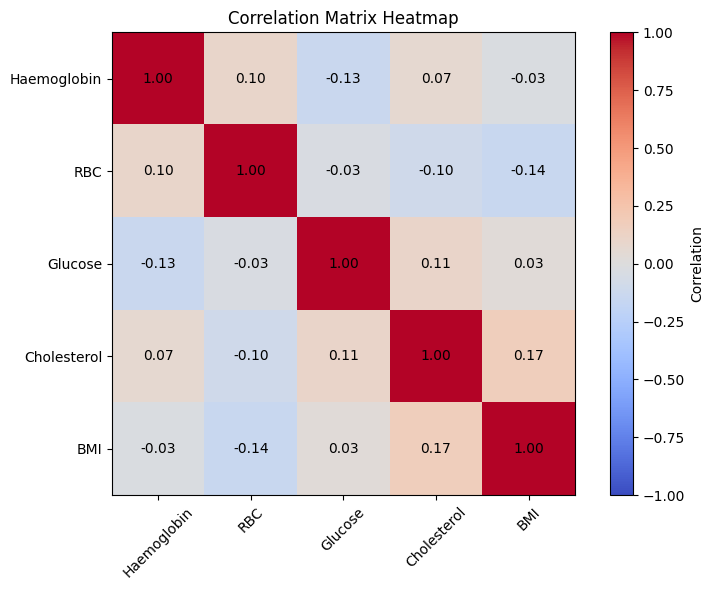


Eigenvalues:
[1.32511405 1.11031401 0.9828869  0.83771742 0.74396762]

Eigenvectors:
[[ 0.24613228 -0.74067287  0.23509617  0.26622328  0.51446823]
 [ 0.50426715 -0.0331167   0.53660467 -0.64546125 -0.20013277]
 [-0.36174773  0.45018115  0.66229107  0.10017661  0.46670193]
 [-0.51080366 -0.41117874  0.4104134   0.15383577 -0.61474145]
 [-0.54161955 -0.28031404 -0.2229722  -0.69195675  0.31551793]]

Principal Directions:
First Principal Component:
[ 0.24613228  0.50426715 -0.36174773 -0.51080366 -0.54161955]

Second Principal Component:
[-0.74067287 -0.0331167   0.45018115 -0.41117874 -0.28031404]


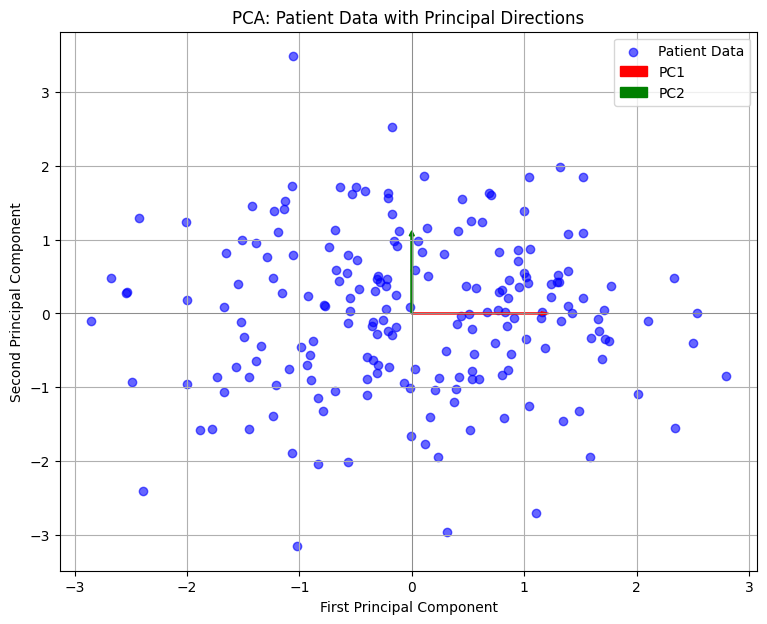


Percentage of Variance Explained:
PC1: 26.50%
PC2: 22.21%
PC3: 19.66%
PC4: 16.75%
PC5: 14.88%

Cumulative Variance:
[ 26.50228096  48.70856109  68.36629917  85.12064756 100.        ]


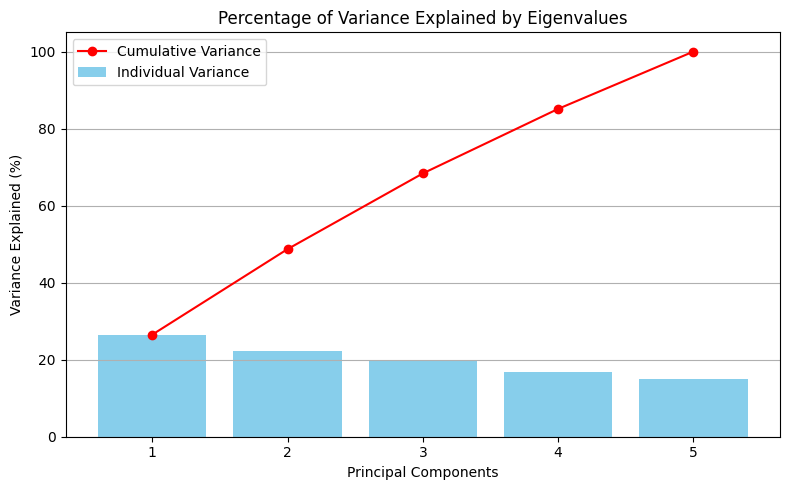

In [3]:

# Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------
# TASK 1: Load Data and Standardise Features
# ------------------------------------------------

# Generate sample dataset of 200 patients
np.random.seed(42)

data = pd.DataFrame({
    'Haemoglobin': np.random.normal(13.5, 1.5, 200),
    'RBC': np.random.normal(4.8, 0.6, 200),
    'Glucose': np.random.normal(110, 20, 200),
    'Cholesterol': np.random.normal(190, 30, 200),
    'BMI': np.random.normal(25, 4, 200)
})

print("Original Dataset:")
print(data.head())

print("\nDataset Shape:", data.shape)

# Standardisation using Z-score
mean = data.mean()
std = data.std()

standardized_data = (data - mean) / std

print("\nStandardised Data:")
print(standardized_data.head())


# ------------------------------------------------
# TASK 2: Covariance and Correlation Matrices
# ------------------------------------------------

# Calculate covariance matrix
cov_matrix = standardized_data.cov()

print("\nCovariance Matrix:")
print(cov_matrix)

# Calculate correlation matrix
corr_matrix = standardized_data.corr()

print("\nCorrelation Matrix:")
print(corr_matrix)

# Plot covariance heatmap
plt.figure(figsize=(8, 6))

plt.imshow(cov_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Covariance')

plt.xticks(range(5), data.columns, rotation=45)
plt.yticks(range(5), data.columns)

plt.title("Covariance Matrix Heatmap")

for i in range(5):
    for j in range(5):
        plt.text(j, i, f'{cov_matrix.iloc[i, j]:.2f}',
                 ha='center', va='center')

plt.tight_layout()
plt.show()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))

plt.imshow(corr_matrix, cmap='coolwarm',
           vmin=-1, vmax=1, interpolation='nearest')
plt.colorbar(label='Correlation')

plt.xticks(range(5), data.columns, rotation=45)
plt.yticks(range(5), data.columns)

plt.title("Correlation Matrix Heatmap")

for i in range(5):
    for j in range(5):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                 ha='center', va='center')

plt.tight_layout()
plt.show()


# ------------------------------------------------
# TASK 3: Eigenvalues and Eigenvectors
# ------------------------------------------------

# Convert covariance matrix into NumPy array
cov_array = cov_matrix.to_numpy()

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_array)

# Sort eigenvalues in descending order
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

# Principal components
print("\nPrincipal Directions:")
print("First Principal Component:")
print(eigenvectors[:, 0])

print("\nSecond Principal Component:")
print(eigenvectors[:, 1])


# ------------------------------------------------
# TASK 4: Plot Data in 2-D with Eigenvectors
# ------------------------------------------------

# Project standardised data onto first two eigenvectors
principal_components = standardized_data.to_numpy() @ eigenvectors[:, :2]

plt.figure(figsize=(9, 7))

# Plot data in principal component space
plt.scatter(
    principal_components[:, 0],
    principal_components[:, 1],
    alpha=0.6,
    color='blue',
    label='Patient Data'
)

# Draw eigenvector arrows
plt.arrow(
    0, 0,
    eigenvalues[0]**0.5, 0,
    color='red',
    width=0.015,
    label='PC1'
)

plt.arrow(
    0, 0,
    0, eigenvalues[1]**0.5,
    color='green',
    width=0.015,
    label='PC2'
)

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")

plt.title("PCA: Patient Data with Principal Directions")

plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)

plt.legend()
plt.grid(True)
plt.show()


# ------------------------------------------------
# TASK 5: Percentage of Variance Explained
# ------------------------------------------------

# Calculate total variance
total_variance = np.sum(eigenvalues)

# Percentage variance explained by each eigenvalue
variance_percentage = (eigenvalues / total_variance) * 100

print("\nPercentage of Variance Explained:")

for i, value in enumerate(variance_percentage):
    print(f"PC{i+1}: {value:.2f}%")

# Cumulative variance
cumulative_variance = np.cumsum(variance_percentage)

print("\nCumulative Variance:")
print(cumulative_variance)

# Plot explained variance
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 6),
    variance_percentage,
    color='skyblue',
    label='Individual Variance'
)

plt.plot(
    range(1, 6),
    cumulative_variance,
    marker='o',
    color='red',
    label='Cumulative Variance'
)

plt.xlabel("Principal Components")
plt.ylabel("Variance Explained (%)")

plt.title("Percentage of Variance Explained by Eigenvalues")

plt.xticks(range(1, 6))
plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()
